# How often should a transformer be checked?
### Daily check-sheet readings vs continuous monitoring for forecasting oil-temperature peaks

**Question.** Many backup and distribution transformers are still monitored with a manual daily check sheet. How much worse is one daily reading than continuous monitoring at anticipating *tomorrow's peak oil temperature*, and how many readings per day close the gap?

**Why oil temperature.** Top-oil temperature is a standard indicator of a transformer's thermal stress and safe loading.

**Data.** Electricity Transformer Dataset (ETDataset), two transformers (ETTm1, ETTm2), July 2016 – June 2018, one row every 15 minutes: oil temperature (`OT`) and six load features.
Source: https://github.com/zhouhaoyi/ETDataset (Zhou et al., *Informer*, AAAI 2021). Licence CC BY-ND 4.0: the data is loaded from the original link and not redistributed.

**Author.** Syed Ali Abbas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/"

def load(name):
    # Read one transformer file; use the timestamp as the index
    df = pd.read_csv(BASE + name + ".csv", parse_dates=["date"]).set_index("date")
    return df

data = {name: load(name) for name in ["ETTm1", "ETTm2"]}
for name, df in data.items():
    print(name, df.shape, "from", df.index.min().date(), "to", df.index.max().date())
data["ETTm1"].head()

ETTm1 (69680, 7) from 2016-07-01 to 2018-06-26
ETTm2 (69680, 7) from 2016-07-01 to 2018-06-26


,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


## Step 1 – Look at the data
Oil temperature follows the seasons over the year. Within a day it moves up and down by a few degrees, and the daily peak comes at different times on different days.

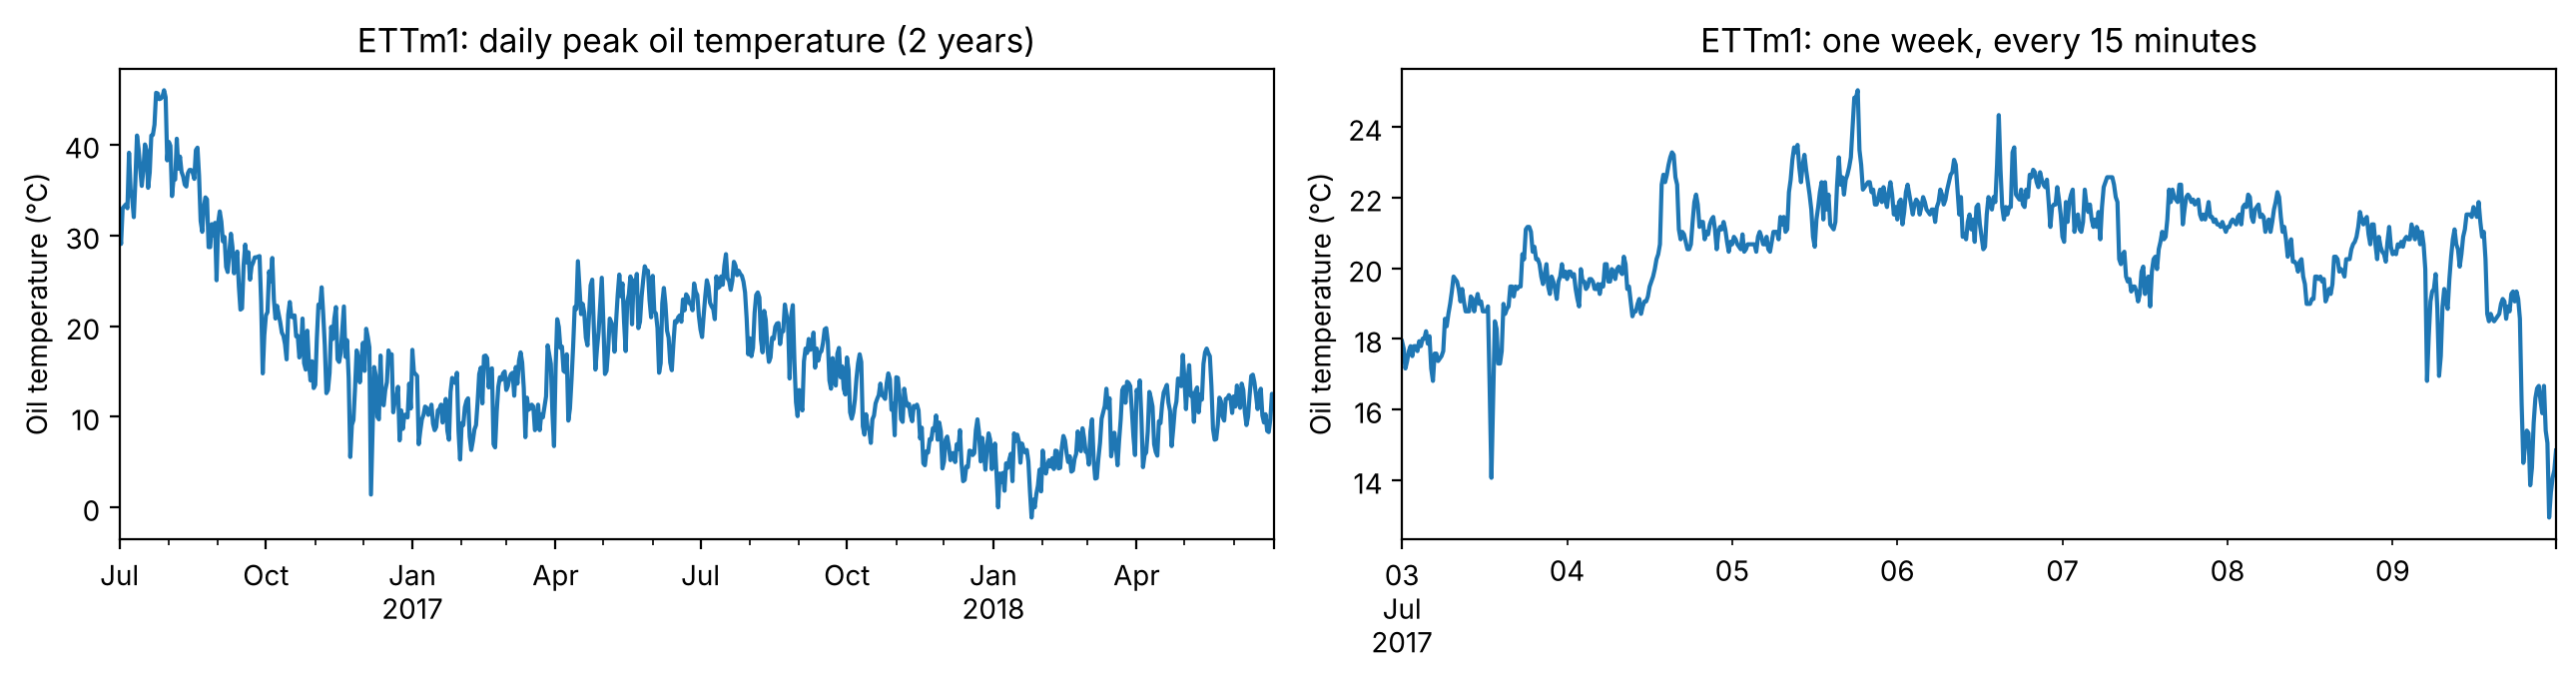

In [2]:
ot = data["ETTm1"]["OT"]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ot.resample("D").max().plot(ax=ax[0], title="ETTm1: daily peak oil temperature (2 years)")
ot["2017-07-03":"2017-07-09"].plot(ax=ax[1], title="ETTm1: one week, every 15 minutes")
for a in ax:
    a.set_ylabel("Oil temperature (°C)"); a.set_xlabel("")
plt.tight_layout(); plt.show()

## Step 2 – Check sheet vs continuous monitoring
**Target:** tomorrow's peak oil temperature.
- **Guess A – check sheet:** tomorrow's peak ≈ today's single 9:00 a.m. reading.
- **Guess B – continuous monitoring:** tomorrow's peak ≈ today's highest 15-minute reading.

Error = mean absolute error (MAE) in °C: on average, how far the guess is from the real peak.

In [3]:
def compare(df):
    ot = df["OT"]
    tomorrow_peak = ot.resample("D").max().shift(-1)           # the value we want to anticipate
    guess_a = ot[ot.index.strftime("%H:%M") == "09:00"]        # one manual reading per day
    guess_a.index = guess_a.index.normalize()                  # label it with the day only
    guess_b = ot.resample("D").max()                           # today's peak from all readings
    t = pd.concat({"tomorrow_peak": tomorrow_peak, "A_checksheet": guess_a, "B_continuous": guess_b}, axis=1).dropna()
    return {"Guess A: 9 a.m. check sheet": (t["A_checksheet"] - t["tomorrow_peak"]).abs().mean(),
            "Guess B: continuous monitoring": (t["B_continuous"] - t["tomorrow_peak"]).abs().mean(),
            "days compared": len(t)}

result = pd.DataFrame({name: compare(df) for name, df in data.items()}).T
result.round(2)

,Guess A: 9 a.m. check sheet,Guess B: continuous monitoring,days compared
ETTm1,3.81,1.98,725.0
ETTm2,8.96,4.09,725.0


## Step 3 – How many readings per day are enough?
We keep 1, 2, 4, 8, 24 or 96 evenly spaced readings per day (starting at 9:00 a.m.) and use the highest of them as the guess for tomorrow's peak. 96 readings = every 15 minutes = continuous monitoring.

                  ETTm1  ETTm2
readings per day              
1                  3.81   8.96
2                  2.80   6.63
4                  2.16   4.12
8                  2.05   4.12
24                 1.98   4.08
96                 1.98   4.09


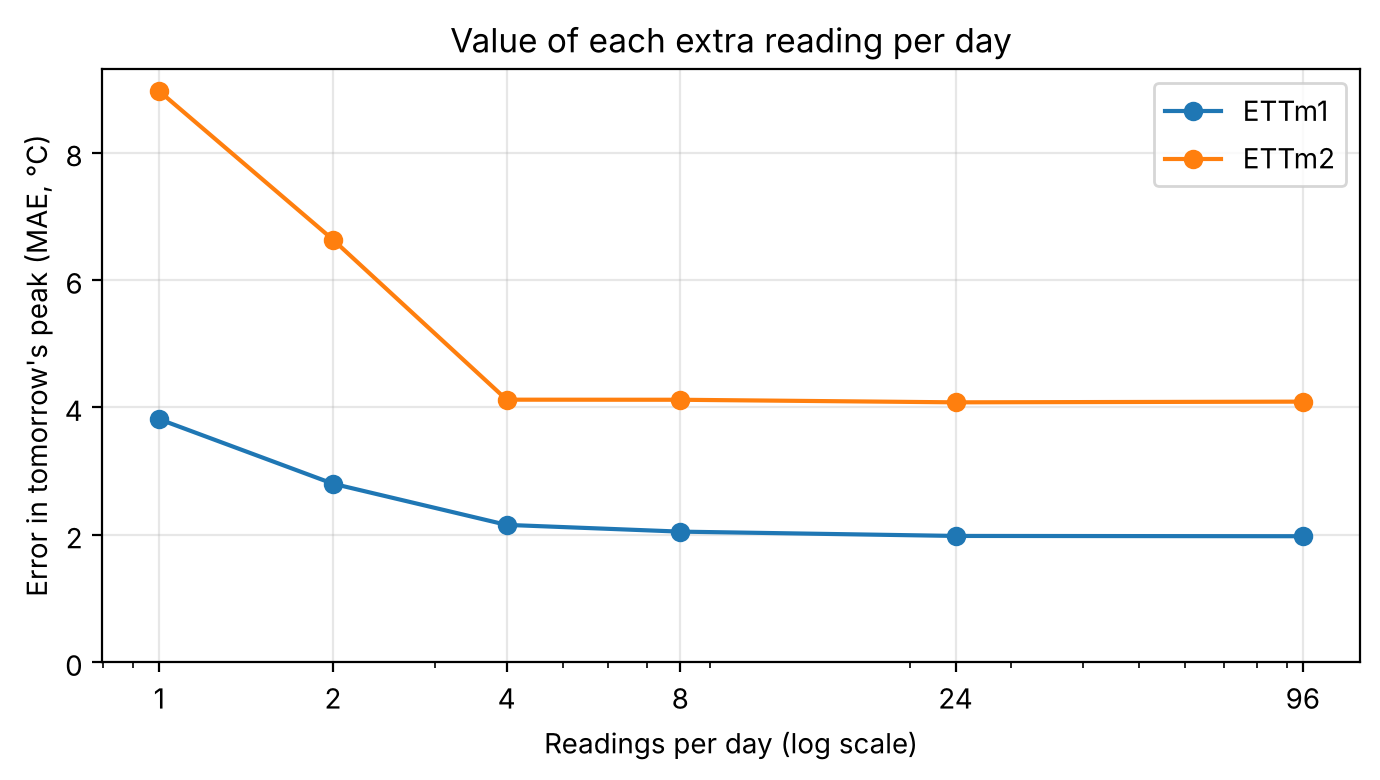

In [4]:
READINGS = [1, 2, 4, 8, 24, 96]

def sweep(df):
    ot = df["OT"]
    tomorrow_peak = ot.resample("D").max().shift(-1)
    slot = ot.index.hour * 4 + ot.index.minute // 15           # 15-minute slot of the day: 0..95
    errors = {}
    for k in READINGS:
        every = 96 // k                                        # slots between two readings
        readings = ot[(slot - 36) % every == 0]                # slot 36 = 09:00
        guess = readings.resample("D").max()
        t = pd.concat([guess, tomorrow_peak], axis=1).dropna()
        errors[k] = (t.iloc[:, 0] - t.iloc[:, 1]).abs().mean()
    return pd.Series(errors)

table = pd.DataFrame({name: sweep(df) for name, df in data.items()})
table.index.name = "readings per day"
print(table.round(2))

ax = table.plot(marker="o", logx=True, figsize=(7, 4))
ax.set_xticks(READINGS); ax.set_xticklabels(READINGS)
ax.set_xlabel("Readings per day (log scale)"); ax.set_ylabel("Error in tomorrow's peak (MAE, °C)")
ax.set_title("Value of each extra reading per day")
ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("readings_per_day.png", dpi=150); plt.show()

## Findings
*(Numbers come from the tables above; re-check them after running.)*

1. One daily reading at 9:00 a.m. is a clearly worse guide to tomorrow's peak than continuous monitoring on both transformers: its error is roughly double (about 3.8 vs 2.0 °C on ETTm1, 9.0 vs 4.1 °C on ETTm2).
2. Most of the gap closes with a few evenly spaced readings per day; beyond about 4 readings per day (one every 6 hours), extra readings add almost nothing for either transformer.
3. The size of the gap differs between the two transformers, so the right monitoring frequency depends on the asset.

## Limits
- Only two transformers, two years, one region; no ambient temperature, no failure records.
- The guesses are deliberately simple (no model yet), so this measures the *information* in the readings, not the best possible forecast.
- A real check sheet has human timing errors and missed days, which are not simulated here.

## Next steps
- Add a simple model (e.g. linear regression with load features) to see if it makes sparse readings more useful.
- Simulate missed or late manual readings.
- Link the monitoring frequency to cost: when is an extra sensor or reading worth it?